# Exploratory analysis

I cleaned the nine tables in the previous notebook. This notebook reads those cleaned files from `data/processed/` and looks at who the customers are, how they pay and watch, and which groups churn.

Each chart has one takeaway printed underneath it. The sentence uses the numbers from that chart, so a later rerun will update the words if the files change.

The churn cuts use `customer_features.csv`. That table is one row per customer, built from these same cleaned files. Tenure runs from registration to the churn date, or to 30 June 2026 if the customer was still subscribed. Week 2 keeps three extra signals that show up here: current plan, failed-payment history, and average feedback rating.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA = PROJECT_ROOT / "data" / "processed"

def strip_text(frame):
    out = frame.copy()
    for column in out.select_dtypes(include="object").columns:
        out[column] = out[column].str.strip()
    return out

customers = strip_text(pd.read_csv(DATA / "customers_clean.csv", parse_dates=["registration_date"]))
plans = strip_text(pd.read_csv(DATA / "subscription_plans_clean.csv"))
subscriptions = strip_text(pd.read_csv(
    DATA / "subscriptions_clean.csv",
    parse_dates=["subscription_start_date", "subscription_end_date", "cancellation_date"],
))
payments = strip_text(pd.read_csv(DATA / "payments_clean.csv", parse_dates=["payment_date"]))
viewing = strip_text(pd.read_csv(DATA / "viewing_activity_clean.csv", parse_dates=["viewing_date"]))
tickets = strip_text(pd.read_csv(DATA / "support_tickets_clean.csv"))
tickets["ticket_date"] = pd.to_datetime(tickets["ticket_date"], errors="coerce")
content = strip_text(pd.read_csv(DATA / "content_clean.csv"))
features = strip_text(pd.read_csv(DATA / "customer_features.csv"))

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "figure.dpi": 110,
})
COLOR = "#4C78A8"

def show_horizontal(series, title, xlabel):
    ordered = series.dropna().sort_values()
    fig, ax = plt.subplots(figsize=(8, max(3.2, 0.34 * len(ordered))))
    ordered.plot.barh(ax=ax, color=COLOR)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    fig.tight_layout()
    plt.show()

def show_vertical(series, title, xlabel, ylabel, rotate=30):
    fig, ax = plt.subplots(figsize=(8, 4.2))
    series.plot.bar(ax=ax, color=COLOR)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=rotate)
    fig.tight_layout()
    plt.show()

def show_line(series, title, xlabel, ylabel):
    fig, ax = plt.subplots(figsize=(8, 4.2))
    plotted = series.copy()
    plotted.index = pd.to_datetime(plotted.index)
    plotted.plot(ax=ax, color=COLOR)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    fig.tight_layout()
    plt.show()

def month_stamp(dates):
    return dates.dt.to_period("M").dt.to_timestamp()

AGE_BANDS = ["Under 18", "18–24", "25–34", "35–44", "45–54", "55–64", "65 and over", "Unknown"]
TENURE_BANDS = ["Under 1 year", "1 to 3 years", "3 to 5 years", "Over 5 years"]
FAILURE_BANDS = ["No failed payments", "1 failed payment", "2 or more failed payments"]
TICKET_BANDS = ["No tickets", "1 ticket", "2 or more tickets"]
ENGAGEMENT_BANDS = ["Low", "Typical", "High"]

def age_band(age):
    if pd.isna(age):
        return "Unknown"
    age = int(age)
    if age <= 17:
        return "Under 18"
    if age <= 24:
        return "18–24"
    if age <= 34:
        return "25–34"
    if age <= 44:
        return "35–44"
    if age <= 54:
        return "45–54"
    if age <= 64:
        return "55–64"
    return "65 and over"

def tenure_bucket(days):
    if pd.isna(days):
        return "Unknown"
    days = int(days)
    if days < 365:
        return TENURE_BANDS[0]
    if days < 365 * 3:
        return TENURE_BANDS[1]
    if days < 365 * 5:
        return TENURE_BANDS[2]
    return TENURE_BANDS[3]

def failure_bucket(count):
    count = 0 if pd.isna(count) else int(count)
    if count <= 0:
        return FAILURE_BANDS[0]
    if count == 1:
        return FAILURE_BANDS[1]
    return FAILURE_BANDS[2]

def ticket_bucket(count):
    count = 0 if pd.isna(count) else int(count)
    if count <= 0:
        return TICKET_BANDS[0]
    if count == 1:
        return TICKET_BANDS[1]
    return TICKET_BANDS[2]

low_cut = float(features["engagement_score"].quantile(0.25))
high_cut = float(features["engagement_score"].quantile(0.75))

def engagement_tier(score):
    if pd.isna(score):
        return "Unknown"
    if score < low_cut:
        return "Low"
    if score > high_cut:
        return "High"
    return "Typical"

features["tenure_bucket"] = features["customer_tenure_days"].map(tenure_bucket)
features["failure_bucket"] = features["failed_payment_count"].map(failure_bucket)
features["ticket_bucket"] = features["support_ticket_count"].map(ticket_bucket)
features["engagement_tier"] = features["engagement_score"].map(engagement_tier)
features["churned"] = features["churned"].map(lambda value: str(value).strip().lower() in {"1", "true", "t", "yes"})
customers["age_band"] = customers["age"].map(age_band)

def churn_table(column, order):
    grouped = (
        features.groupby(column, observed=False)["churned"]
        .agg(customers="count", churned_customers="sum")
        .reindex(order)
    )
    grouped["churn_rate"] = (100 * grouped["churned_customers"] / grouped["customers"]).round(2)
    return grouped

def show_rates(table, title):
    show_vertical(table["churn_rate"], title, "", "Churn rate (%)", rotate=20)

def rate_takeaway(table, label, minimum=50):
    usable = table.dropna(subset=["customers", "churn_rate"])
    usable = usable[usable["customers"] >= minimum]
    highest = usable["churn_rate"].idxmax()
    lowest = usable["churn_rate"].idxmin()
    print(
        "Takeaway: "
        f"among groups of at least {minimum} customers, {highest} has the highest {label} churn rate, "
        f"{usable.loc[highest, 'churn_rate']:.1f}% of {int(usable.loc[highest, 'customers']):,}. "
        f"{lowest} is the lowest, at {usable.loc[lowest, 'churn_rate']:.1f}% "
        f"of {int(usable.loc[lowest, 'customers']):,}."
    )

print(
    f"Loaded {len(customers):,} customers, {len(subscriptions):,} subscriptions, "
    f"{len(payments):,} payments, {len(viewing):,} viewing rows, and {len(tickets):,} tickets."
)


Matplotlib is building the font cache; this may take a moment.


Loaded 8,000 customers, 8,875 subscriptions, 110,735 payments, 66,422 viewing rows, and 6,120 tickets.


/var/folders/6m/3f3cqkg51zl9pp5099kh259w0000gp/T/ipykernel_30044/3005344759.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in out.select_dtypes(include="object").columns:
/var/folders/6m/3f3cqkg51zl9pp5099kh259w0000gp/T/ipykernel_30044/3005344759.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pand

## 1. Customer distribution

Country, age, and acquisition channel. Age bands use the cleaned customer file, so a missing age stays Unknown instead of being filled in.


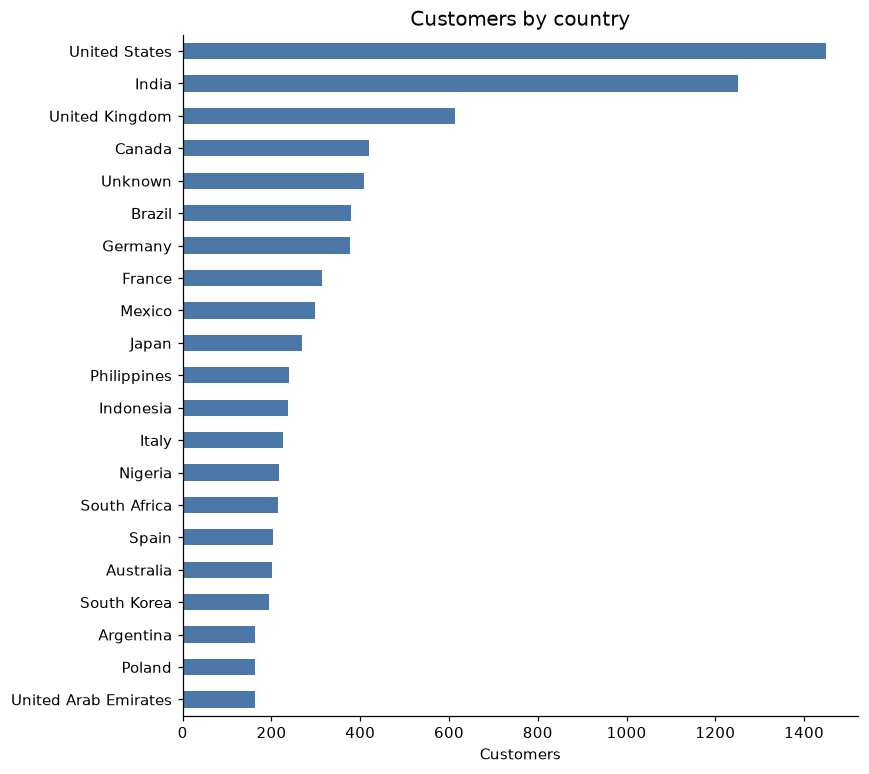

Takeaway: United States is the largest country, with 1,449 of 8,000 customers.


In [2]:
by_country = customers["country"].fillna("Unknown").value_counts()
show_horizontal(by_country, "Customers by country", "Customers")
top_country = by_country.idxmax()
print(
    f"Takeaway: {top_country} is the largest country, with {int(by_country.max()):,} "
    f"of {int(by_country.sum()):,} customers."
)


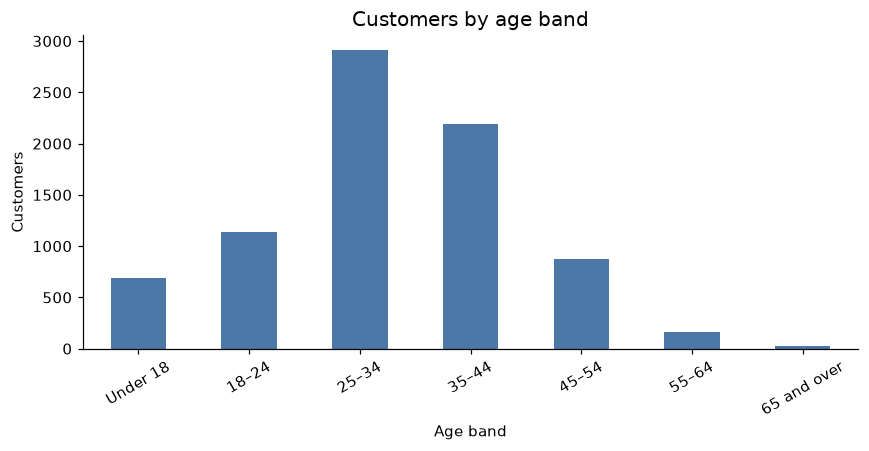

Takeaway: 25–34 is the largest age band, with 2,911 customers. The cleaning step already filled missing ages, so no customer sits in an Unknown band.


In [3]:
age_order = [band for band in AGE_BANDS if (customers["age_band"] == band).any()]
by_age = customers["age_band"].value_counts().reindex(age_order)
show_vertical(by_age, "Customers by age band", "Age band", "Customers")
peak_age = by_age.idxmax()
unknown_age = int((customers["age_band"] == "Unknown").sum())
if unknown_age:
    age_note = f"{unknown_age:,} customers still have no age."
else:
    age_note = "The cleaning step already filled missing ages, so no customer sits in an Unknown band."
print(f"Takeaway: {peak_age} is the largest age band, with {int(by_age.max()):,} customers. {age_note}")


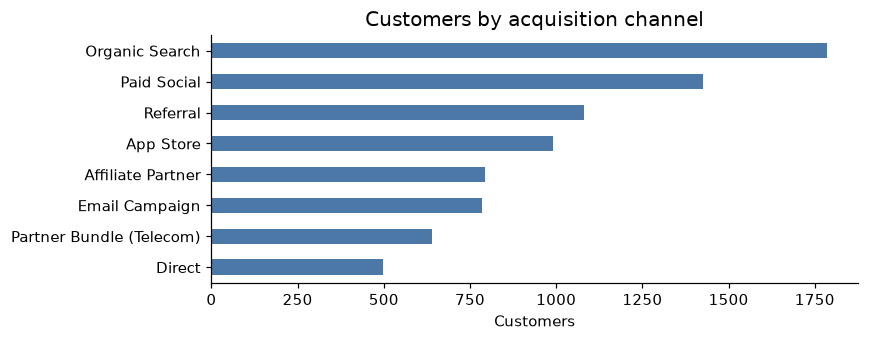

Takeaway: Organic Search brought in the most customers, 1,786 of 8,000.


In [4]:
by_channel = customers["acquisition_channel"].fillna("Unknown").value_counts()
show_horizontal(by_channel, "Customers by acquisition channel", "Customers")
top_channel = by_channel.idxmax()
print(
    f"Takeaway: {top_channel} brought in the most customers, "
    f"{int(by_channel.max()):,} of {int(by_channel.sum()):,}."
)


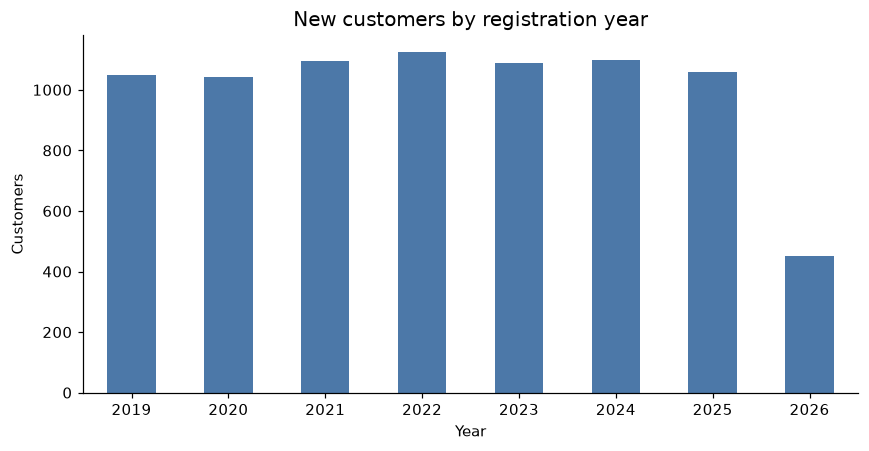

Takeaway: 2022 has the most signups, 1,124 customers. The first year in the file is 2019 and the last is 2026.


In [5]:
signups = customers.groupby(customers["registration_date"].dt.year).size()
signups.index = signups.index.astype(int)
show_vertical(signups, "New customers by registration year", "Year", "Customers", rotate=0)
print(
    f"Takeaway: {int(signups.idxmax())} has the most signups, {int(signups.max()):,} customers. "
    f"The first year in the file is {int(signups.index.min())} and the last is {int(signups.index.max())}."
)


## 2. Plan distribution and revenue mix

Current plan is the plan on the customer feature row. Revenue counts successful payments only, joined to the subscription that payment was matched to.


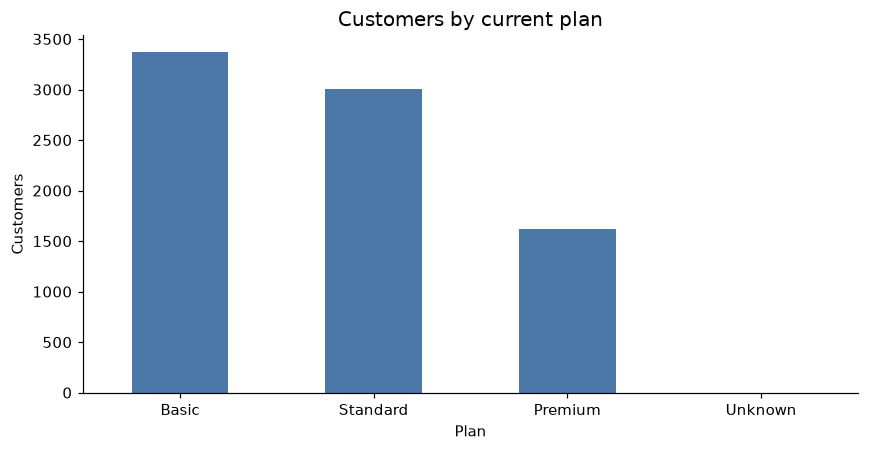

Takeaway: Basic is the most common current plan, 3,369 of 8,000 customers.


In [6]:
by_plan = features["current_plan_name"].fillna("Unknown").value_counts()
show_vertical(by_plan, "Customers by current plan", "Plan", "Customers", rotate=0)
print(
    f"Takeaway: {by_plan.idxmax()} is the most common current plan, "
    f"{int(by_plan.max()):,} of {int(by_plan.sum()):,} customers."
)


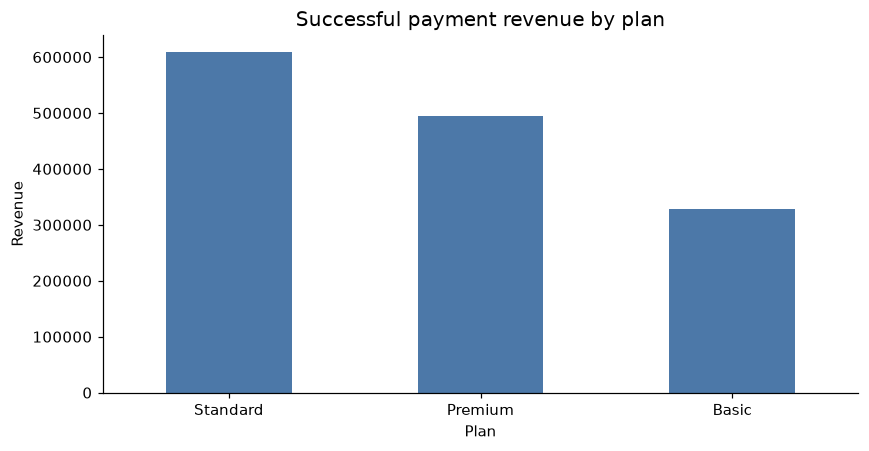

Takeaway: Standard brings in the most successful-payment revenue, 608,561 of 1,430,511.


In [7]:
successful = payments.loc[payments["payment_status"].str.lower() == "success", ["subscription_id", "amount", "payment_date"]].copy()
plan_lookup = subscriptions.merge(plans[["plan_id", "plan_name"]], on="plan_id", how="left")
successful = successful.merge(plan_lookup[["subscription_id", "plan_name"]], on="subscription_id", how="left")
successful["plan_name"] = successful["plan_name"].fillna("Unknown")
revenue_by_plan = successful.groupby("plan_name")["amount"].sum().sort_values(ascending=False)
show_vertical(revenue_by_plan, "Successful payment revenue by plan", "Plan", "Revenue", rotate=0)
print(
    f"Takeaway: {revenue_by_plan.idxmax()} brings in the most successful-payment revenue, "
    f"{revenue_by_plan.max():,.0f} of {revenue_by_plan.sum():,.0f}."
)


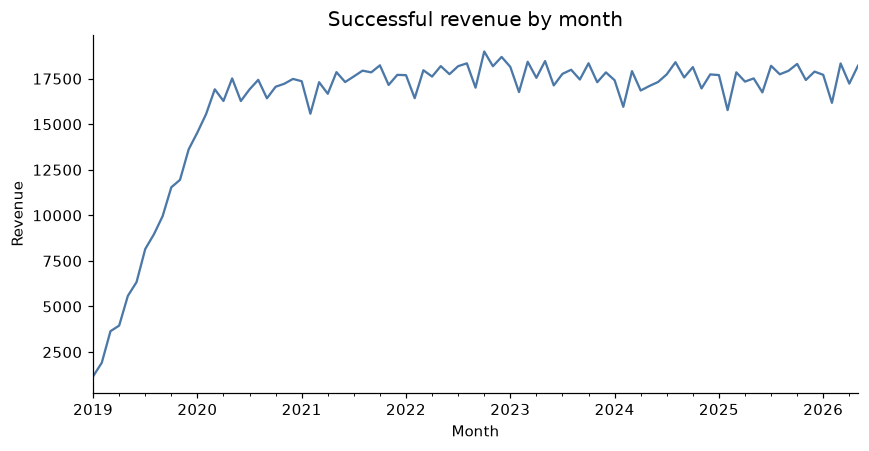

Takeaway: successful revenue runs from Jan 2019 to May 2026. The highest month is Oct 2022 at 18,993.


In [8]:
monthly_revenue = successful.groupby(month_stamp(successful["payment_date"]))["amount"].sum().sort_index()
show_line(monthly_revenue, "Successful revenue by month", "Month", "Revenue")
print(
    f"Takeaway: successful revenue runs from {monthly_revenue.index.min():%b %Y} "
    f"to {monthly_revenue.index.max():%b %Y}. "
    f"The highest month is {monthly_revenue.idxmax():%b %Y} at {monthly_revenue.max():,.0f}."
)


## 3. Cancellations

A cancellation is a subscription row with a cancellation date. Plan changes that did not cancel are left out of these three charts.


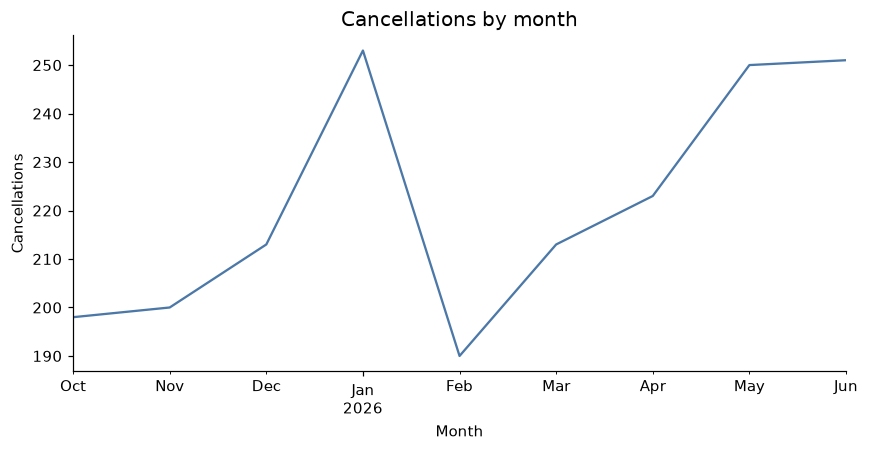

Takeaway: 1,991 subscriptions have a cancellation date, from Oct 2025 to Jun 2026. The busiest month is Jan 2026 with 253.


In [9]:
cancelled = subscriptions.dropna(subset=["cancellation_date"]).merge(
    plans[["plan_id", "plan_name"]], on="plan_id", how="left"
)
cancelled["plan_name"] = cancelled["plan_name"].fillna("Unknown")
cancellations_by_month = cancelled.groupby(month_stamp(cancelled["cancellation_date"])).size().sort_index()
show_line(cancellations_by_month, "Cancellations by month", "Month", "Cancellations")
print(
    f"Takeaway: {len(cancelled):,} subscriptions have a cancellation date, "
    f"from {cancellations_by_month.index.min():%b %Y} to {cancellations_by_month.index.max():%b %Y}. "
    f"The busiest month is {cancellations_by_month.idxmax():%b %Y} with {int(cancellations_by_month.max()):,}."
)


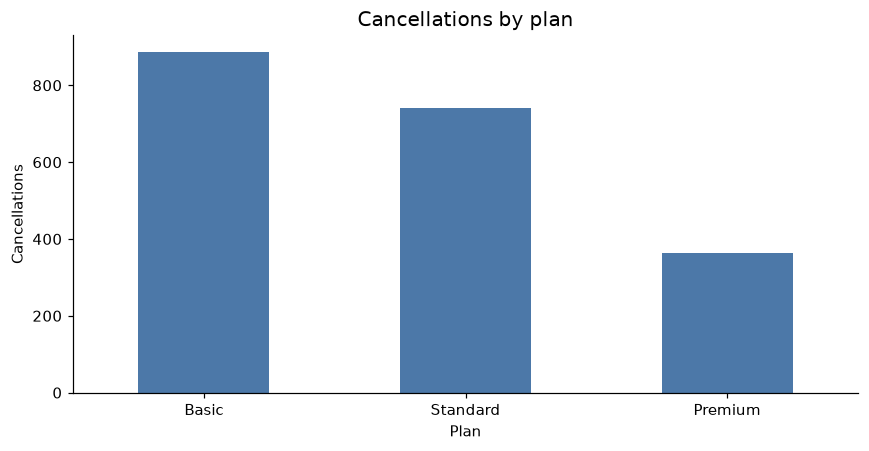

Takeaway: Basic accounts for 886 of 1,991 cancellations.


In [10]:
cancellations_by_plan = cancelled["plan_name"].value_counts()
show_vertical(cancellations_by_plan, "Cancellations by plan", "Plan", "Cancellations", rotate=0)
print(
    f"Takeaway: {cancellations_by_plan.idxmax()} accounts for {int(cancellations_by_plan.max()):,} "
    f"of {int(cancellations_by_plan.sum()):,} cancellations."
)


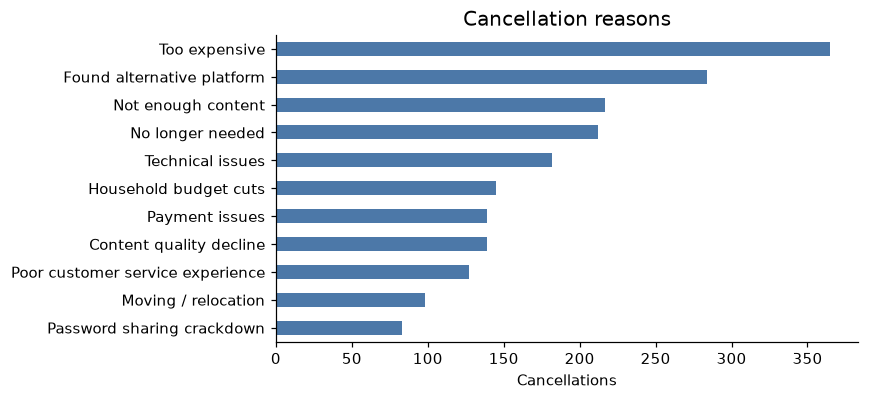

Takeaway: the most common stated reason is Too expensive, 365 of 1,991 cancellations.


In [11]:
reasons = cancelled["cancellation_reason"].fillna("Unknown").value_counts()
show_horizontal(reasons, "Cancellation reasons", "Cancellations")
print(
    f"Takeaway: the most common stated reason is {reasons.idxmax()}, "
    f"{int(reasons.max()):,} of {int(reasons.sum()):,} cancellations."
)


## 4. Watching

Watch time and completion come from viewing activity. Device and genre labels are the cleaned values.


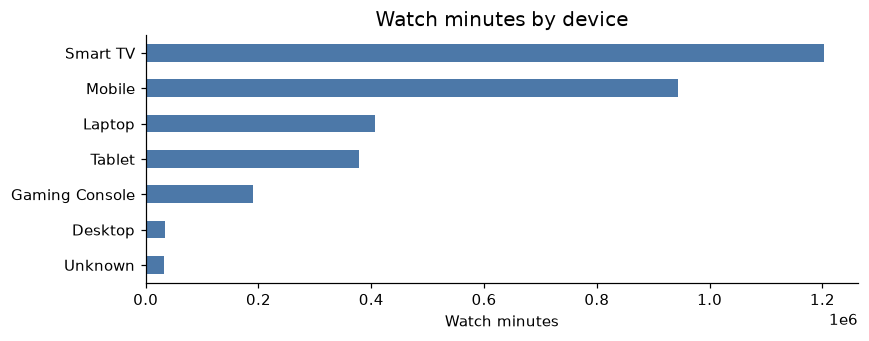

Takeaway: Smart TV accounts for 1,202,903 of 3,187,861 watch minutes.


In [12]:
watch_by_device = viewing.groupby(viewing["device_type"].fillna("Unknown"))["watch_duration_minutes"].sum().sort_values(ascending=False)
show_horizontal(watch_by_device, "Watch minutes by device", "Watch minutes")
print(
    f"Takeaway: {watch_by_device.idxmax()} accounts for {watch_by_device.max():,.0f} "
    f"of {watch_by_device.sum():,.0f} watch minutes."
)


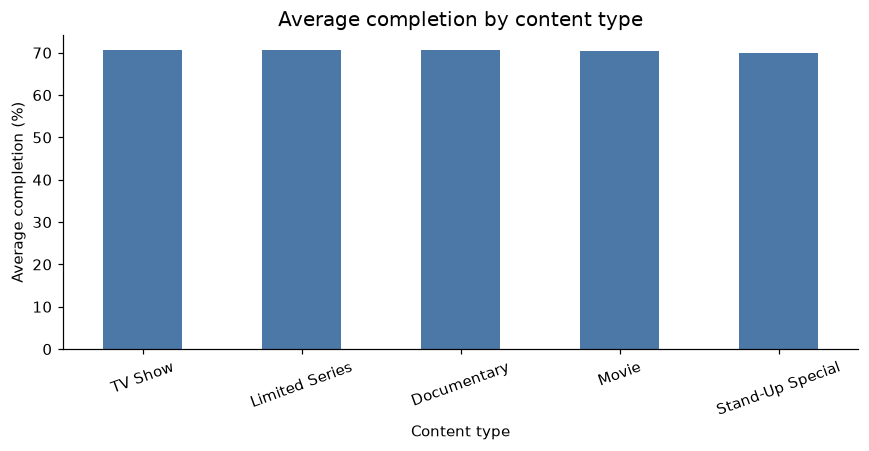

Takeaway: average completion only spans 0.8 points, from 69.8% for Stand-Up Special to 70.6% for TV Show. Content type barely separates completion.


In [13]:
watched = viewing.merge(content[["content_id", "content_type", "genre"]], on="content_id", how="left")
completion = watched.groupby(watched["content_type"].fillna("Unknown"))["completion_percentage"].mean().sort_values(ascending=False)
show_vertical(completion, "Average completion by content type", "Content type", "Average completion (%)", rotate=20)
spread = completion.max() - completion.min()
print(
    f"Takeaway: average completion only spans {spread:.1f} points, "
    f"from {completion.min():.1f}% for {completion.idxmin()} to {completion.max():.1f}% for {completion.idxmax()}. "
    "Content type barely separates completion."
)


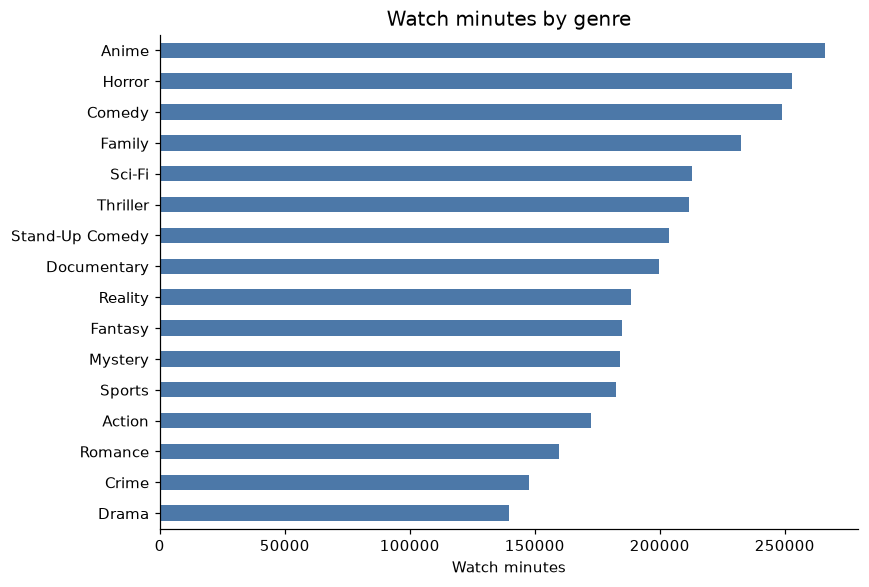

Takeaway: Anime is the most-watched genre, 266,007 of 3,187,861 minutes.


In [14]:
watch_by_genre = watched.groupby(watched["genre"].fillna("Unknown"))["watch_duration_minutes"].sum().sort_values(ascending=False)
show_horizontal(watch_by_genre, "Watch minutes by genre", "Watch minutes")
print(
    f"Takeaway: {watch_by_genre.idxmax()} is the most-watched genre, "
    f"{watch_by_genre.max():,.0f} of {watch_by_genre.sum():,.0f} minutes."
)


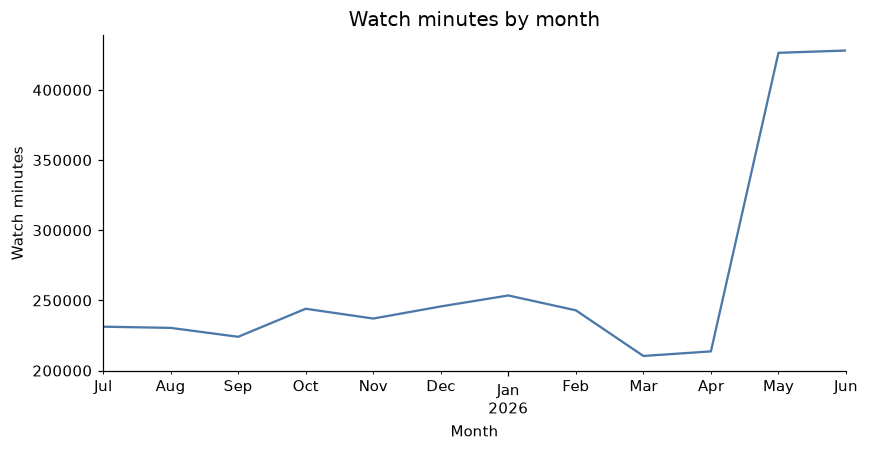

Takeaway: viewing runs from Jul 2025 to Jun 2026. The highest month is Jun 2026 at 428,081 minutes.


In [15]:
monthly_watch = viewing.groupby(month_stamp(viewing["viewing_date"]))["watch_duration_minutes"].sum().sort_index()
show_line(monthly_watch, "Watch minutes by month", "Month", "Watch minutes")
print(
    f"Takeaway: viewing runs from {monthly_watch.index.min():%b %Y} to {monthly_watch.index.max():%b %Y}. "
    f"The highest month is {monthly_watch.idxmax():%b %Y} at {monthly_watch.max():,.0f} minutes."
)


## 5. Who churns

Churn rate here is the share of customers in the group whose churn label is true. The overall rate is printed first so the later bars have something to sit against.

Engagement tiers are the bottom quarter, the middle half, and the top quarter of `engagement_score` in this file. Low means below the 25th percentile. High means above the 75th.


In [16]:
overall = 100 * features["churned"].mean()
print(f"Overall churn rate: {overall:.2f}% of {len(features):,} customers.")
print(f"Engagement tiers split at {low_cut:.3f} and {high_cut:.3f}.")


Overall churn rate: 24.89% of 8,000 customers.
Engagement tiers split at 0.531 and 0.570.


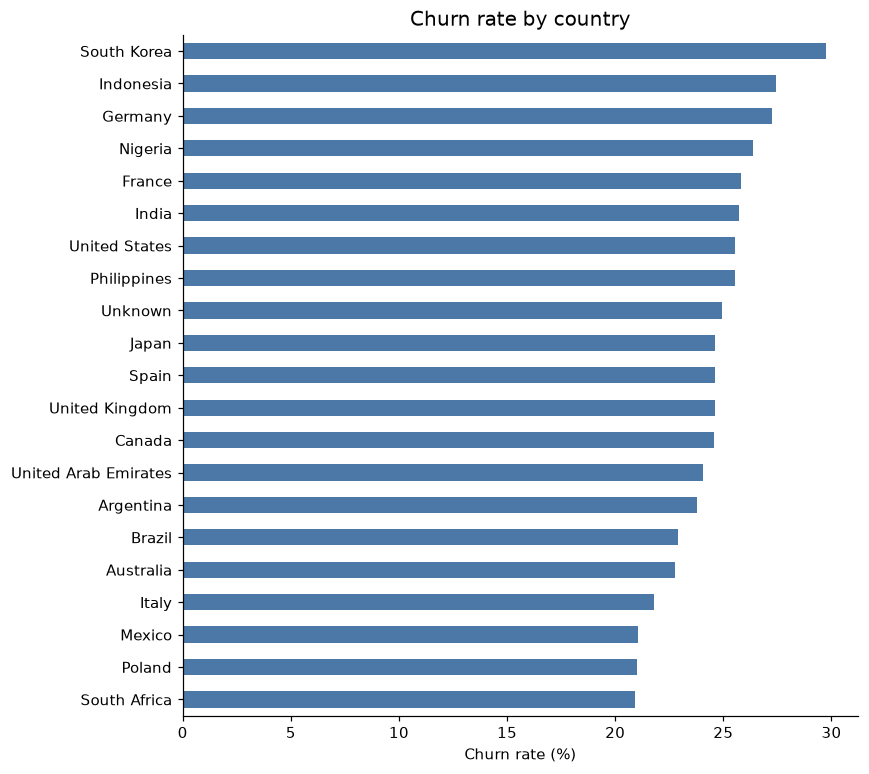

Takeaway: among groups of at least 50 customers, South Korea has the highest country churn rate, 29.7% of 195. South Africa is the lowest, at 20.9% of 215.


In [17]:
country_order = features["country"].fillna("Unknown").value_counts().index.tolist()
features["country"] = features["country"].fillna("Unknown")
by_country_churn = churn_table("country", country_order)
show_horizontal(by_country_churn["churn_rate"], "Churn rate by country", "Churn rate (%)")
rate_takeaway(by_country_churn, "country")


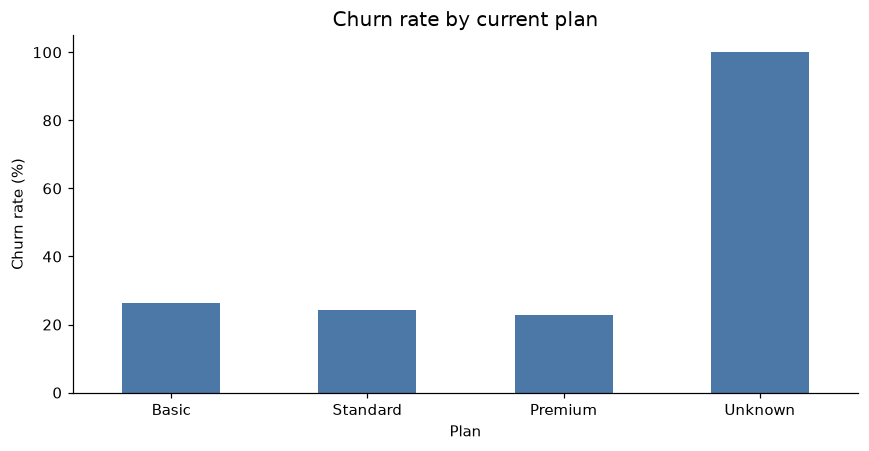

Takeaway: among groups of at least 50 customers, Basic has the highest plan churn rate, 26.3% of 3,369. Premium is the lowest, at 22.8% of 1,620.


In [18]:
plan_order = features["current_plan_name"].fillna("Unknown").value_counts().index.tolist()
features["current_plan_name"] = features["current_plan_name"].fillna("Unknown")
by_plan_churn = churn_table("current_plan_name", plan_order)
show_vertical(by_plan_churn["churn_rate"], "Churn rate by current plan", "Plan", "Churn rate (%)", rotate=0)
rate_takeaway(by_plan_churn, "plan")


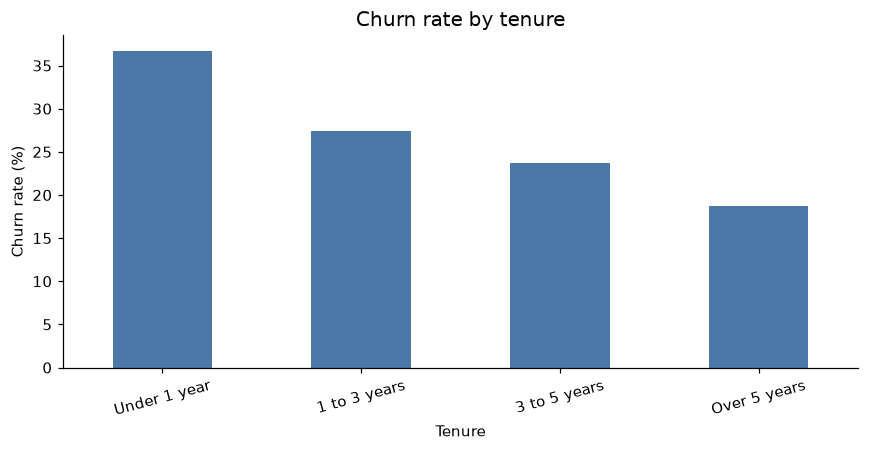

Takeaway: among groups of at least 50 customers, Under 1 year has the highest tenure churn rate, 36.7% of 1,107. Over 5 years is the lowest, at 18.7% of 2,580.


In [19]:
by_tenure = churn_table("tenure_bucket", TENURE_BANDS)
show_vertical(by_tenure["churn_rate"], "Churn rate by tenure", "Tenure", "Churn rate (%)", rotate=15)
rate_takeaway(by_tenure, "tenure")


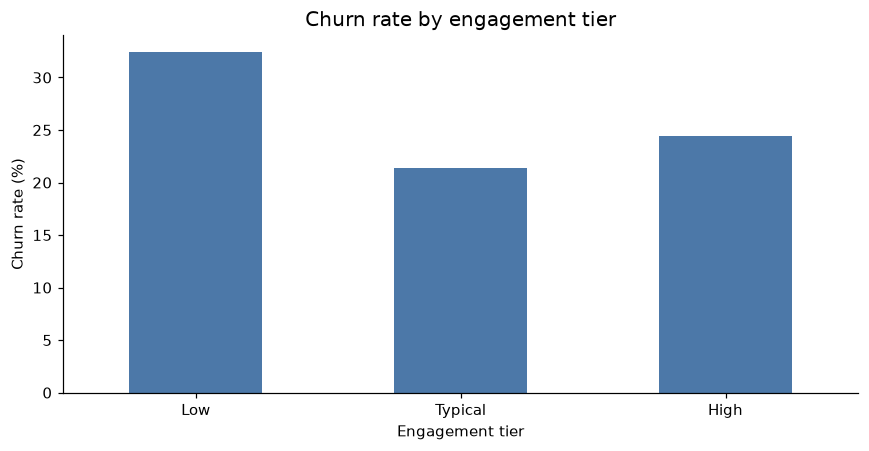

Takeaway: among groups of at least 50 customers, Low has the highest engagement churn rate, 32.4% of 2,000. Typical is the lowest, at 21.4% of 4,000.


In [20]:
by_engagement = churn_table("engagement_tier", ENGAGEMENT_BANDS)
show_vertical(by_engagement["churn_rate"], "Churn rate by engagement tier", "Engagement tier", "Churn rate (%)", rotate=0)
rate_takeaway(by_engagement, "engagement")


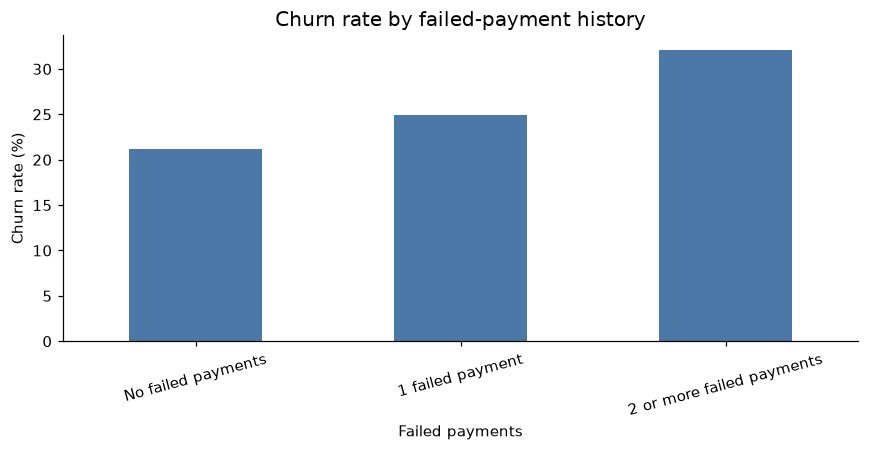

Takeaway: among groups of at least 50 customers, 2 or more failed payments has the highest payment-history churn rate, 32.1% of 1,800. No failed payments is the lowest, at 21.2% of 3,505.


In [21]:
by_failure = churn_table("failure_bucket", FAILURE_BANDS)
show_vertical(by_failure["churn_rate"], "Churn rate by failed-payment history", "Failed payments", "Churn rate (%)", rotate=15)
rate_takeaway(by_failure, "payment-history")


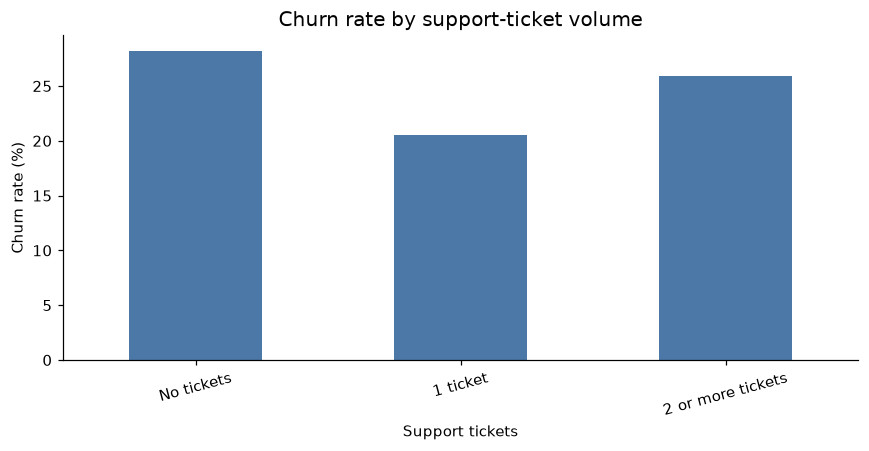

Takeaway: among groups of at least 50 customers, No tickets has the highest ticket-volume churn rate, 28.2% of 3,781. 1 ticket is the lowest, at 20.6% of 3,170.


In [22]:
by_tickets = churn_table("ticket_bucket", TICKET_BANDS)
show_vertical(by_tickets["churn_rate"], "Churn rate by support-ticket volume", "Support tickets", "Churn rate (%)", rotate=15)
rate_takeaway(by_tickets, "ticket-volume")


## 6. Support trends

Ticket dates that could not be parsed stay out of the monthly charts. The takeaway says how many those are. Resolution time is the average of tickets that have a recorded time.


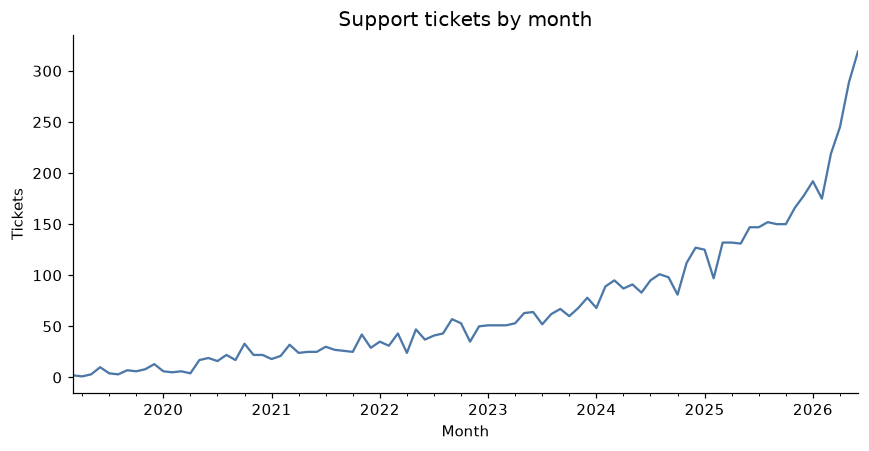

Takeaway: 6,059 tickets have a usable date, from Mar 2019 to Jun 2026. 61 tickets have an unusable date and are left out. The busiest month is Jun 2026 with 319 tickets.


In [23]:
missing_dates = int(tickets["ticket_date"].isna().sum())
dated = tickets.dropna(subset=["ticket_date"])
ticket_volume = dated.groupby(month_stamp(dated["ticket_date"])).size().sort_index()
show_line(ticket_volume, "Support tickets by month", "Month", "Tickets")
print(
    f"Takeaway: {len(dated):,} tickets have a usable date, from {ticket_volume.index.min():%b %Y} "
    f"to {ticket_volume.index.max():%b %Y}. {missing_dates:,} tickets have an unusable date and are left out. "
    f"The busiest month is {ticket_volume.idxmax():%b %Y} with {int(ticket_volume.max()):,} tickets."
)


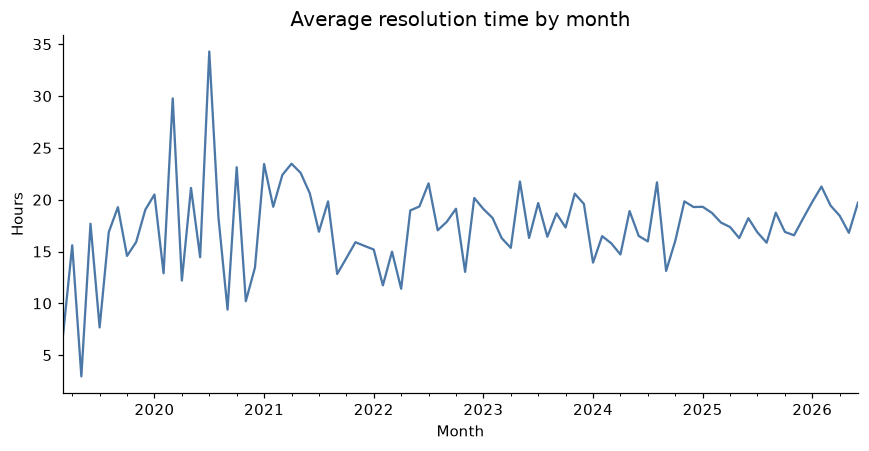

Takeaway: average resolution time across 4,547 timed tickets is 18.0 hours. The slowest month in this chart is Jul 2020 at 34.3 hours.


In [24]:
timed = dated.dropna(subset=["resolution_time_hours"])
resolution = timed.groupby(month_stamp(timed["ticket_date"]))["resolution_time_hours"].mean().sort_index()
show_line(resolution, "Average resolution time by month", "Month", "Hours")
print(
    f"Takeaway: average resolution time across {len(timed):,} timed tickets is {timed['resolution_time_hours'].mean():.1f} hours. "
    f"The slowest month in this chart is {resolution.idxmax():%b %Y} at {resolution.max():.1f} hours."
)


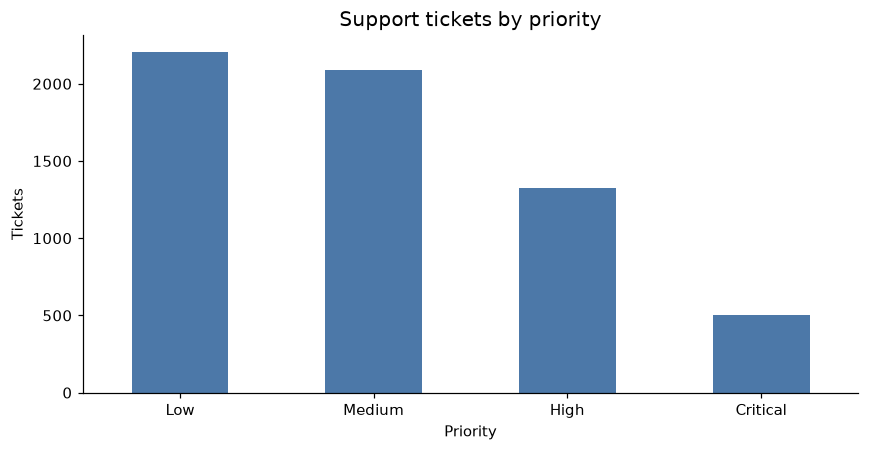

Takeaway: Low is the most common priority, 2,204 of 6,120 tickets.


In [25]:
by_priority = tickets["priority"].fillna("Unknown").value_counts()
show_vertical(by_priority, "Support tickets by priority", "Priority", "Tickets", rotate=0)
print(
    f"Takeaway: {by_priority.idxmax()} is the most common priority, "
    f"{int(by_priority.max()):,} of {int(by_priority.sum()):,} tickets."
)


## 7. Complaints and satisfaction

Category counts use every ticket. Satisfaction uses Resolved and Closed tickets that have a score. The last two charts are the feedback rating and the average successful payment, split by whether the customer churned. Those are two of the extra features kept for the models.


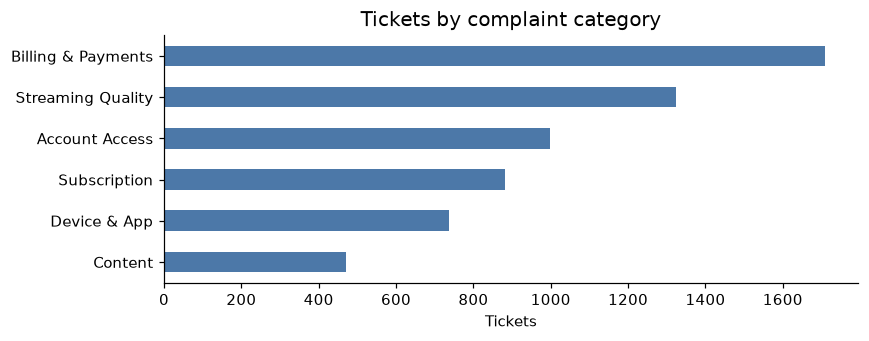

Takeaway: Billing & Payments is the most common complaint, 1,709 of 6,120 tickets.


In [26]:
by_category = tickets["issue_category"].fillna("Unknown").value_counts()
show_horizontal(by_category, "Tickets by complaint category", "Tickets")
print(
    f"Takeaway: {by_category.idxmax()} is the most common complaint, "
    f"{int(by_category.max()):,} of {int(by_category.sum()):,} tickets."
)


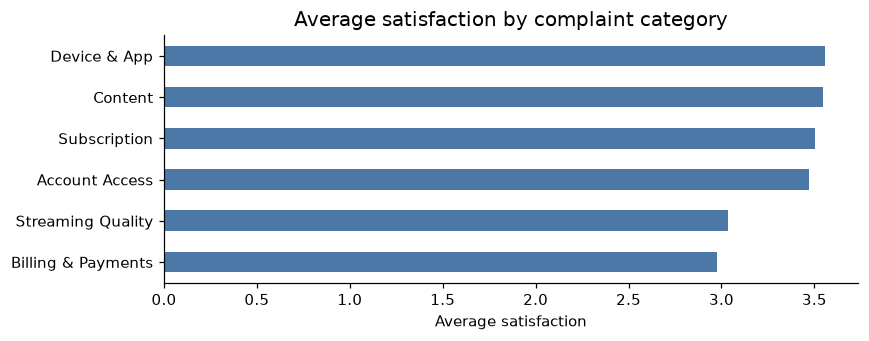

Takeaway: among 4,592 scored Resolved or Closed tickets, Billing & Payments has the lowest average satisfaction at 2.98. Device & App is highest at 3.56.


In [27]:
scored = tickets.loc[
    tickets["ticket_status"].isin(["Resolved", "Closed"])
    & tickets["customer_satisfaction_score"].notna()
].copy()
csat_by_category = scored.groupby("issue_category")["customer_satisfaction_score"].mean().sort_values()
show_horizontal(csat_by_category, "Average satisfaction by complaint category", "Average satisfaction")
print(
    f"Takeaway: among {len(scored):,} scored Resolved or Closed tickets, "
    f"{csat_by_category.idxmin()} has the lowest average satisfaction at {csat_by_category.min():.2f}. "
    f"{csat_by_category.idxmax()} is highest at {csat_by_category.max():.2f}."
)


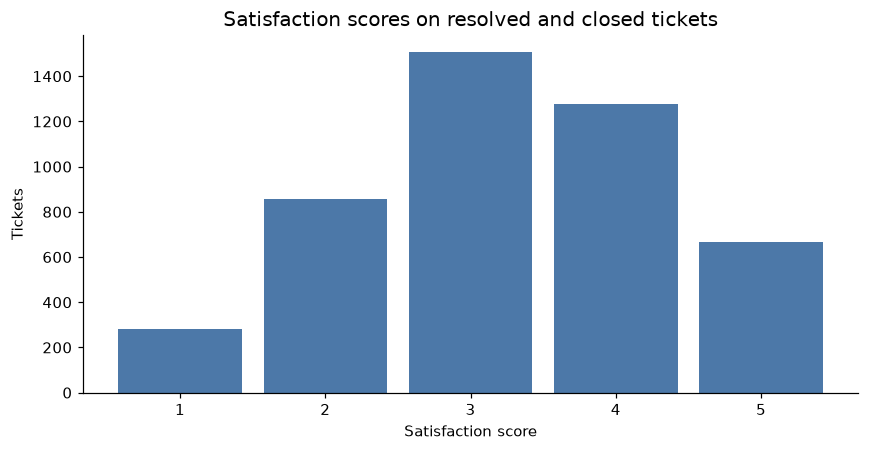

Takeaway: the mean satisfaction score is 3.26 across 4,592 tickets. The most common score is 3.


In [28]:
fig, ax = plt.subplots(figsize=(8, 4.2))
scored["customer_satisfaction_score"].plot.hist(ax=ax, bins=range(1, 7), align="left", rwidth=0.85, color=COLOR)
ax.set_title("Satisfaction scores on resolved and closed tickets")
ax.set_xlabel("Satisfaction score")
ax.set_ylabel("Tickets")
fig.tight_layout()
plt.show()
print(
    f"Takeaway: the mean satisfaction score is {scored['customer_satisfaction_score'].mean():.2f} "
    f"across {len(scored):,} tickets. The most common score is {int(scored['customer_satisfaction_score'].mode().iloc[0])}."
)


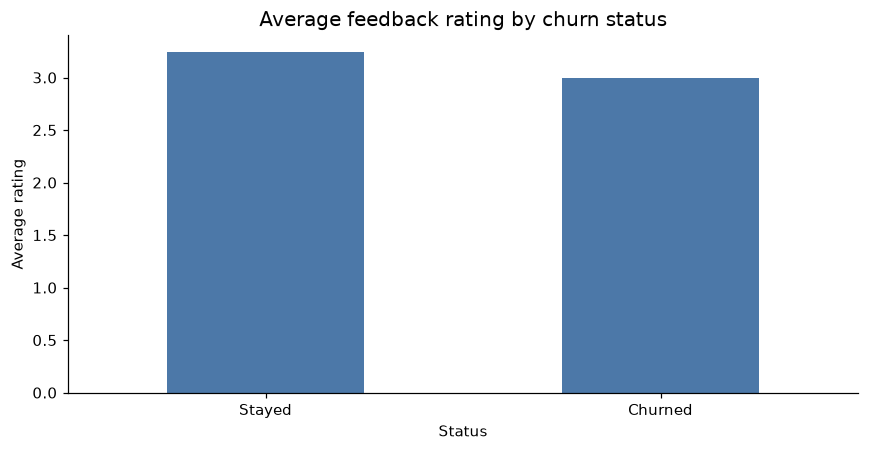

Takeaway: among 3,437 customers who left feedback, those who stayed average 3.24 and those who churned average 2.99.


In [29]:
rated = features.dropna(subset=["avg_feedback_rating"]).copy()
rated["status"] = rated["churned"].map({True: "Churned", False: "Stayed"})
rating_by_status = rated.groupby("status")["avg_feedback_rating"].mean().reindex(["Stayed", "Churned"])
show_vertical(rating_by_status, "Average feedback rating by churn status", "Status", "Average rating", rotate=0)
print(
    f"Takeaway: among {len(rated):,} customers who left feedback, "
    f"those who stayed average {rating_by_status['Stayed']:.2f} and those who churned average {rating_by_status['Churned']:.2f}."
)


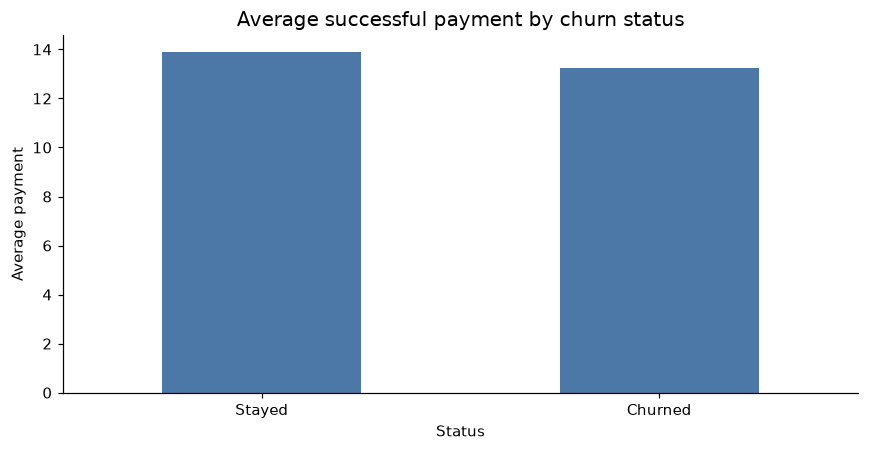

Takeaway: customers who stayed average 13.88 per successful payment. Customers who churned average 13.25.


In [30]:
features["status"] = features["churned"].map({True: "Churned", False: "Stayed"})
payment_by_status = features.groupby("status")["avg_successful_payment_amount"].mean().reindex(["Stayed", "Churned"])
show_vertical(payment_by_status, "Average successful payment by churn status", "Status", "Average payment", rotate=0)
print(
    f"Takeaway: customers who stayed average {payment_by_status['Stayed']:.2f} per successful payment. "
    f"Customers who churned average {payment_by_status['Churned']:.2f}."
)


## What I take into the models

The charts above are why the later feature table keeps current plan, failed-payment history, and average feedback rating. Plan and payment history separate churn rates. Feedback rating is a bit lower for customers who churned, and it is missing for anyone who never left a review. Lifetime value stays a sum of past successful payments, which is why the revenue charts count Success only.
